# Intro to Data Visualization (Fall 2026) - Assignment 4

**The Baby Spike: A Radial Visualization of Birth Times**

Group members: Amar Preet Singh, Samridh Barthaval, Prakash Periyasamy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Question 1 - Radial Design - The Baby Spike

### Data preparation

`births.csv` has one row per birth in the USA in 2022, with the year, the month and the time of birth
as `HH:MM`. We turn each time into a minute of the day (0 to 1439), count how many births happened in
each minute across the whole year, and divide by 365 to get the average number of babies born in that
minute on a typical day.

In [2]:
births = pd.read_csv("births.csv")

birth_hour = births["time"].str.slice(0, 2).astype(int)
birth_minute = births["time"].str.slice(3, 5).astype(int)
births["minute_of_day"] = birth_hour * 60 + birth_minute

assert births["minute_of_day"].between(0, 1439).all()

minutes_per_day = 1440
days_in_year = 365

births_per_minute = (
    births["minute_of_day"]
    .value_counts()
    .reindex(range(minutes_per_day), fill_value=0)
    .sort_index()
    / days_in_year
)

average_per_minute = len(births) / (minutes_per_day * days_in_year)

print(f"Total births in 2022: {len(births):,}")
print(f"Average babies born per minute: {average_per_minute:.2f}")
print(f"Busiest minute: {births_per_minute.idxmax() // 60:02d}:{births_per_minute.idxmax() % 60:02d} "
      f"with {births_per_minute.max():.2f} babies per minute")
print(f"Quietest minute: {births_per_minute.idxmin() // 60:02d}:{births_per_minute.idxmin() % 60:02d} "
      f"with {births_per_minute.min():.2f} babies per minute")

Total births in 2022: 3,675,635
Average babies born per minute: 6.99
Busiest minute: 08:03 with 13.69 babies per minute
Quietest minute: 05:08 with 4.59 babies per minute


### Colour bands

The gap between the yellow average line and the actual data is coloured in discrete bands. Three bands
make up a 25% change from the average, so every band is `average * 0.25 / 3` babies per minute thick
(about 0.58). Blue/teal bands are used below the average and orange/red bands above it. The colour
closest to the average line is the lightest, and the colours get darker the further the data moves
away from the average. The last colour in each list is used for anything beyond it.

In [3]:
below_average_colours = ["#17B09C", "#318F9D", "#2D7AA2", "#226192", "#094E81"]
above_average_colours = ["#FBA41B", "#EF901E", "#EE8320", "#EC7323", "#E66024", "#DB4F28",
                         "#D03D26", "#BE3326", "#AD2A24", "#9B1E1F", "#8D181B", "#7B1515"]
average_line_colour = "#FFDE00"
axis_colour = "grey"

band_step = average_per_minute * 0.25 / 3
axis_radius = 11

### Drawing the radial plot

We use a Matplotlib polar axis. Midnight is placed at the top (`set_theta_zero_location("N")`) and time
runs clockwise (`set_theta_direction(-1)`), so the 24 hours read like a clock face. The radius is the
number of babies born per minute.

- **Gradient:** for each band we call `fill_between()` from the band's inner edge to the data, with the
  data clipped (`np.clip`) to the band's outer edge. Where the data never reaches a band, the clipped
  values equal the inner edge and nothing is drawn. Stacking all bands gives the stepped gradient.
- **The first point is repeated at 2π** so the shape closes at midnight without a gap.
- **Angular axis at 11 babies per minute:** Matplotlib's built-in polar spine always sits on the outer
  edge of the plot, so we turn the default axis off and draw our own circle at radius 11 with a dot
  for every hour and the hour labels just outside it. The radial limit goes up to 14 so the 8 a.m.
  spike can pass through the axis, like in the original.
- **The "8" label is left out** because the spike covers that spot in the original design.
- The average line and the dashed 6 and 9 per minute lines are drawn as full circles.

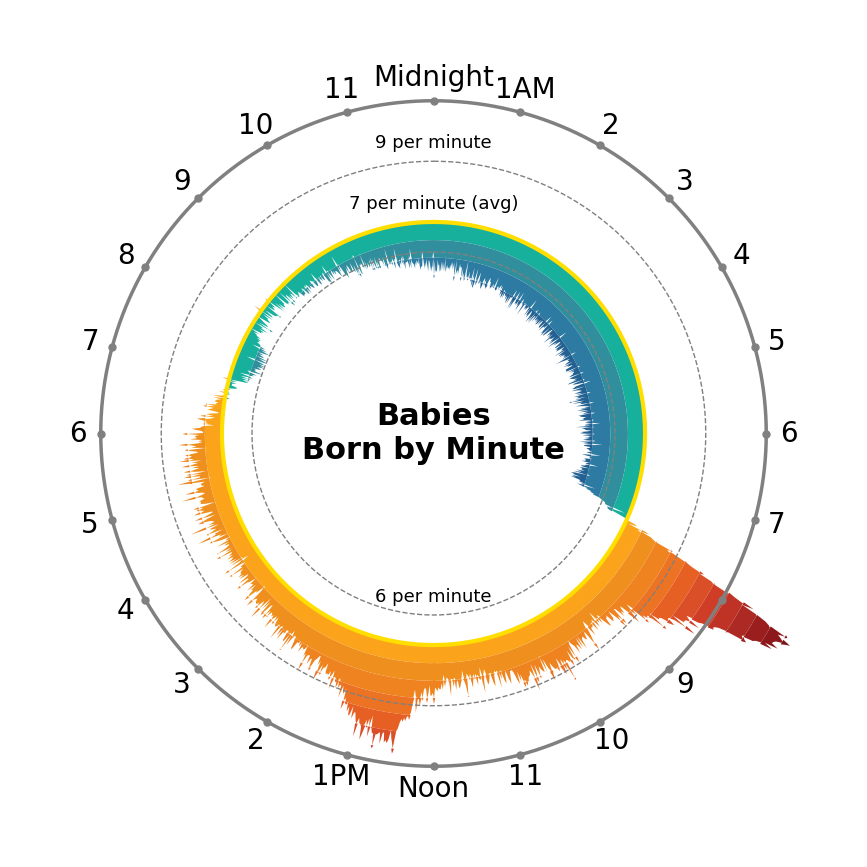

In [4]:
theta = np.append(births_per_minute.index.to_numpy(), minutes_per_day) / minutes_per_day * 2 * np.pi
radius = np.append(births_per_minute.to_numpy(), births_per_minute.iloc[0])

fig, ax = plt.subplots(figsize=(11, 11), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_ylim(0, 14)
ax.axis("off")

# Bands above the average: each band runs from its inner edge up to the data, capped at its outer edge.
for band, colour in enumerate(above_average_colours):
    band_inner = average_per_minute + band * band_step
    is_last_band = band == len(above_average_colours) - 1
    band_outer = np.inf if is_last_band else average_per_minute + (band + 1) * band_step
    ax.fill_between(theta, band_inner, np.clip(radius, band_inner, band_outer),
                    color=colour, linewidth=0, zorder=2)

# Bands below the average: same idea, going inwards from the average line.
for band, colour in enumerate(below_average_colours):
    band_outer = average_per_minute - band * band_step
    is_last_band = band == len(below_average_colours) - 1
    band_inner = 0 if is_last_band else average_per_minute - (band + 1) * band_step
    ax.fill_between(theta, np.clip(radius, band_inner, band_outer), band_outer,
                    color=colour, linewidth=0, zorder=2)

full_circle = np.linspace(0, 2 * np.pi, 721)

ax.plot(full_circle, np.full_like(full_circle, average_per_minute),
        color=average_line_colour, linewidth=3, zorder=3)
for reference_level in (6, 9):
    ax.plot(full_circle, np.full_like(full_circle, reference_level),
            color=axis_colour, linewidth=1, linestyle="--", zorder=4)

# Custom angular axis at 11 babies per minute, with a circle tick mark for each hour.
hour_angles = np.arange(24) / 24 * 2 * np.pi
hour_labels = (["Midnight", "1AM"] + [str(hour) for hour in range(2, 12)]
               + ["Noon", "1PM"] + [str(hour) for hour in range(2, 12)])

ax.plot(full_circle, np.full_like(full_circle, axis_radius), color=axis_colour, linewidth=2.5, zorder=5)
ax.plot(hour_angles, np.full(24, axis_radius), "o", color=axis_colour, markersize=5, zorder=6)
for hour, (angle, label) in enumerate(zip(hour_angles, hour_labels)):
    if hour == 8:
        continue
    ax.text(angle, axis_radius + 0.75, label, ha="center", va="center", fontsize=20)

ax.text(0, 9.6, "9 per minute", ha="center", va="center", fontsize=13)
ax.text(0, average_per_minute + 0.6, f"{average_per_minute:.0f} per minute (avg)",
        ha="center", va="center", fontsize=13)
ax.text(np.pi, 5.4, "6 per minute", ha="center", va="center", fontsize=13)
ax.text(0, 0, "Babies\nBorn by Minute", ha="center", va="center", fontsize=22, fontweight="bold")

plt.show()

Attribution
The birth data comes from the National Center for Health Statistics at the CDC (https://www.cdc.gov/nchs/data_access/vitalstatsonline.htm). We used the births.csv file that came with the assignment.
The design isn’t ours. It’s The Baby Spike by Nadieh Bremer and Zan Armstrong, made for Scientific American (https://www.visualcinnamon.com/portfolio/baby-spike/). We tried to match the Matplotlib version of it shown in the assignment handout.
The gradient colours, the rule that three bands make a 25% change, and the tip to use fill_between() all come straight from the handout.
We used the Matplotlib docs on polar axes a lot to work out how to get a clock-style layout (https://matplotlib.org/stable/gallery/pie_and_polar_charts/index.html).
We also used an AI assistant to help write and debug the code, compare our figure with the reference image in the handout, and draft parts of the report. We went through everything it produced and we’re responsible for what we submitted.